In [1]:
import numpy as np
import scanpy as sc
import rapids_singlecell as rsc
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from pprint import pprint

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from scatlastb_utils.io import read_anndata, write_zarr
from scatlastb_utils.pipeline.misc import dask_compute

/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cuda module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.driver module instead.
/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jup

# Read data

## Read hyperparameters

In [2]:
hyperparams = pd.read_table('data/pipeline/feature_selection/HICA/clustering/input_files.tsv')

In [3]:
hyperparams = hyperparams.query('dataset == "DC"').copy()
hyperparams['integration'] = hyperparams['file_id'].str.split('--').str[1]
hyperparams['hyperparams'] = hyperparams['file_path'].str.split('var_mask~').str[1]

In [4]:
hyperparams

,dataset,file_id,file_path,integration,hyperparams
84,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=083b75bad5,extra_hvgs--batch_key=library_id--flavor=seura...
85,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=4d25c03dfb,extra_hvgs--batch_key=library_id--flavor=seura...
86,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=320d25d4b8,extra_hvgs--batch_key=library_id--flavor=cell_...
87,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=62b15d803a,highly_variable--batch_key=library_id--flavor=...
88,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=69ea542976,highly_variable--batch_key=library_id--flavor=...
89,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=60dd06bb37,highly_variable--batch_key=library_id--flavor=...
90,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=ed7ff5be06,extra_hvgs--batch_key=library_id--flavor=seura...
91,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=52de149d5c,extra_hvgs--batch_key=library_id--flavor=seura...
92,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=17b99232e4,extra_hvgs--batch_key=library_id--flavor=cell_...
93,DC,integration:preprocessing:filter:DC--integrati...,data/pipeline/feature_selection/HICA/integrati...,integration=cdaecea886,highly_variable--batch_key=library_id--flavor=...


In [5]:
pprint(
    hyperparams.set_index('integration')['hyperparams'].to_dict()
)

{'integration=083b75bad5': 'extra_hvgs--batch_key=library_id--flavor=seurat--n_top_genes=5000--span=1/method~unintegrated--hyperparams~None--label~None--output_type~embed.zarr',
 'integration=17b99232e4': 'extra_hvgs--batch_key=library_id--flavor=cell_ranger--n_top_genes=5000--span=1/method~harmony_pytorch--hyperparams~c606b8bfe0--label~None--output_type~embed.zarr',
 'integration=320d25d4b8': 'extra_hvgs--batch_key=library_id--flavor=cell_ranger--n_top_genes=5000--span=1/method~unintegrated--hyperparams~None--label~None--output_type~embed.zarr',
 'integration=3dfc58e3b8': 'highly_variable--batch_key=library_id--flavor=seurat--n_top_genes=5000--span=1/method~drvi--hyperparams~4e1bac1491--label~None--output_type~embed.zarr',
 'integration=4c98c5850e': 'highly_variable--batch_key=library_id--flavor=seurat_v3_paper--n_top_genes=5000--span=1/method~harmony_pytorch--hyperparams~c606b8bfe0--label~None--output_type~embed.zarr',
 'integration=4d25c03dfb': 'extra_hvgs--batch_key=library_id--fla

In [6]:
pprint(
    hyperparams.query('hyperparams.str.contains("drvi")').set_index('integration')['hyperparams'].to_dict()
)

{'integration=3dfc58e3b8': 'highly_variable--batch_key=library_id--flavor=seurat--n_top_genes=5000--span=1/method~drvi--hyperparams~4e1bac1491--label~None--output_type~embed.zarr',
 'integration=59ed3c7a39': 'highly_variable--batch_key=library_id--flavor=seurat_v3_paper--n_top_genes=5000--span=1/method~drvi--hyperparams~4e1bac1491--label~None--output_type~embed.zarr',
 'integration=7966cf414b': 'extra_hvgs--batch_key=library_id--flavor=seurat_v3_paper--n_top_genes=5000--span=1/method~drvi--hyperparams~4e1bac1491--label~None--output_type~embed.zarr',
 'integration=7c1ff8c4c6': 'extra_hvgs--batch_key=library_id--flavor=seurat--n_top_genes=5000--span=1/method~drvi--hyperparams~4e1bac1491--label~None--output_type~embed.zarr',
 'integration=c0d0864c86': 'extra_hvgs--batch_key=library_id--flavor=cell_ranger--n_top_genes=5000--span=1/method~drvi--hyperparams~4e1bac1491--label~None--output_type~embed.zarr',
 'integration=d656b999b3': 'highly_variable--batch_key=library_id--flavor=cell_ranger--

In [7]:
integration_map = {
    'seurat': '7c1ff8c4c6',
    'cell_ranger': 'c0d0864c86',
    'seurat_v3_paper': '7966cf414b',
}

## Read DC integration

In [8]:
file_path = 'data/pipeline/feature_selection/HICA/majority_voting/dataset~DC/file_id~collect:DC.zarr'

In [9]:
adata = read_anndata(
    file_path,
    dask=True,
    backed=True,
    X='layers/normcounts',
    layers='layers',
    obs='obs',
    var='var',
    obsm='obsm',
    dask_slots=['X', 'layers'],
    uns='uns',
    # select_keys=
)

dask: True, backed: True
chunks: (200000, -1)
Read slot "layers/normcounts", store as "X"...
Read layers/normcounts as backed sparse dask array...
Read slot "layers", store as "layers"...


Read layers slots as_dask=True: 100%|██████████| 2/2 [00:00<00:00, 229.62it/s]

Read slot "obs", store as "obs"...


Read slot "var", store as "var"...
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 36/36 [00:02<00:00, 16.20it/s]

Read slot "uns", store as "uns"...



Read uns slots as_dask=False: 100%|██████████| 204/204 [00:15<00:00, 13.35it/s]

shape: (101382, 36601)


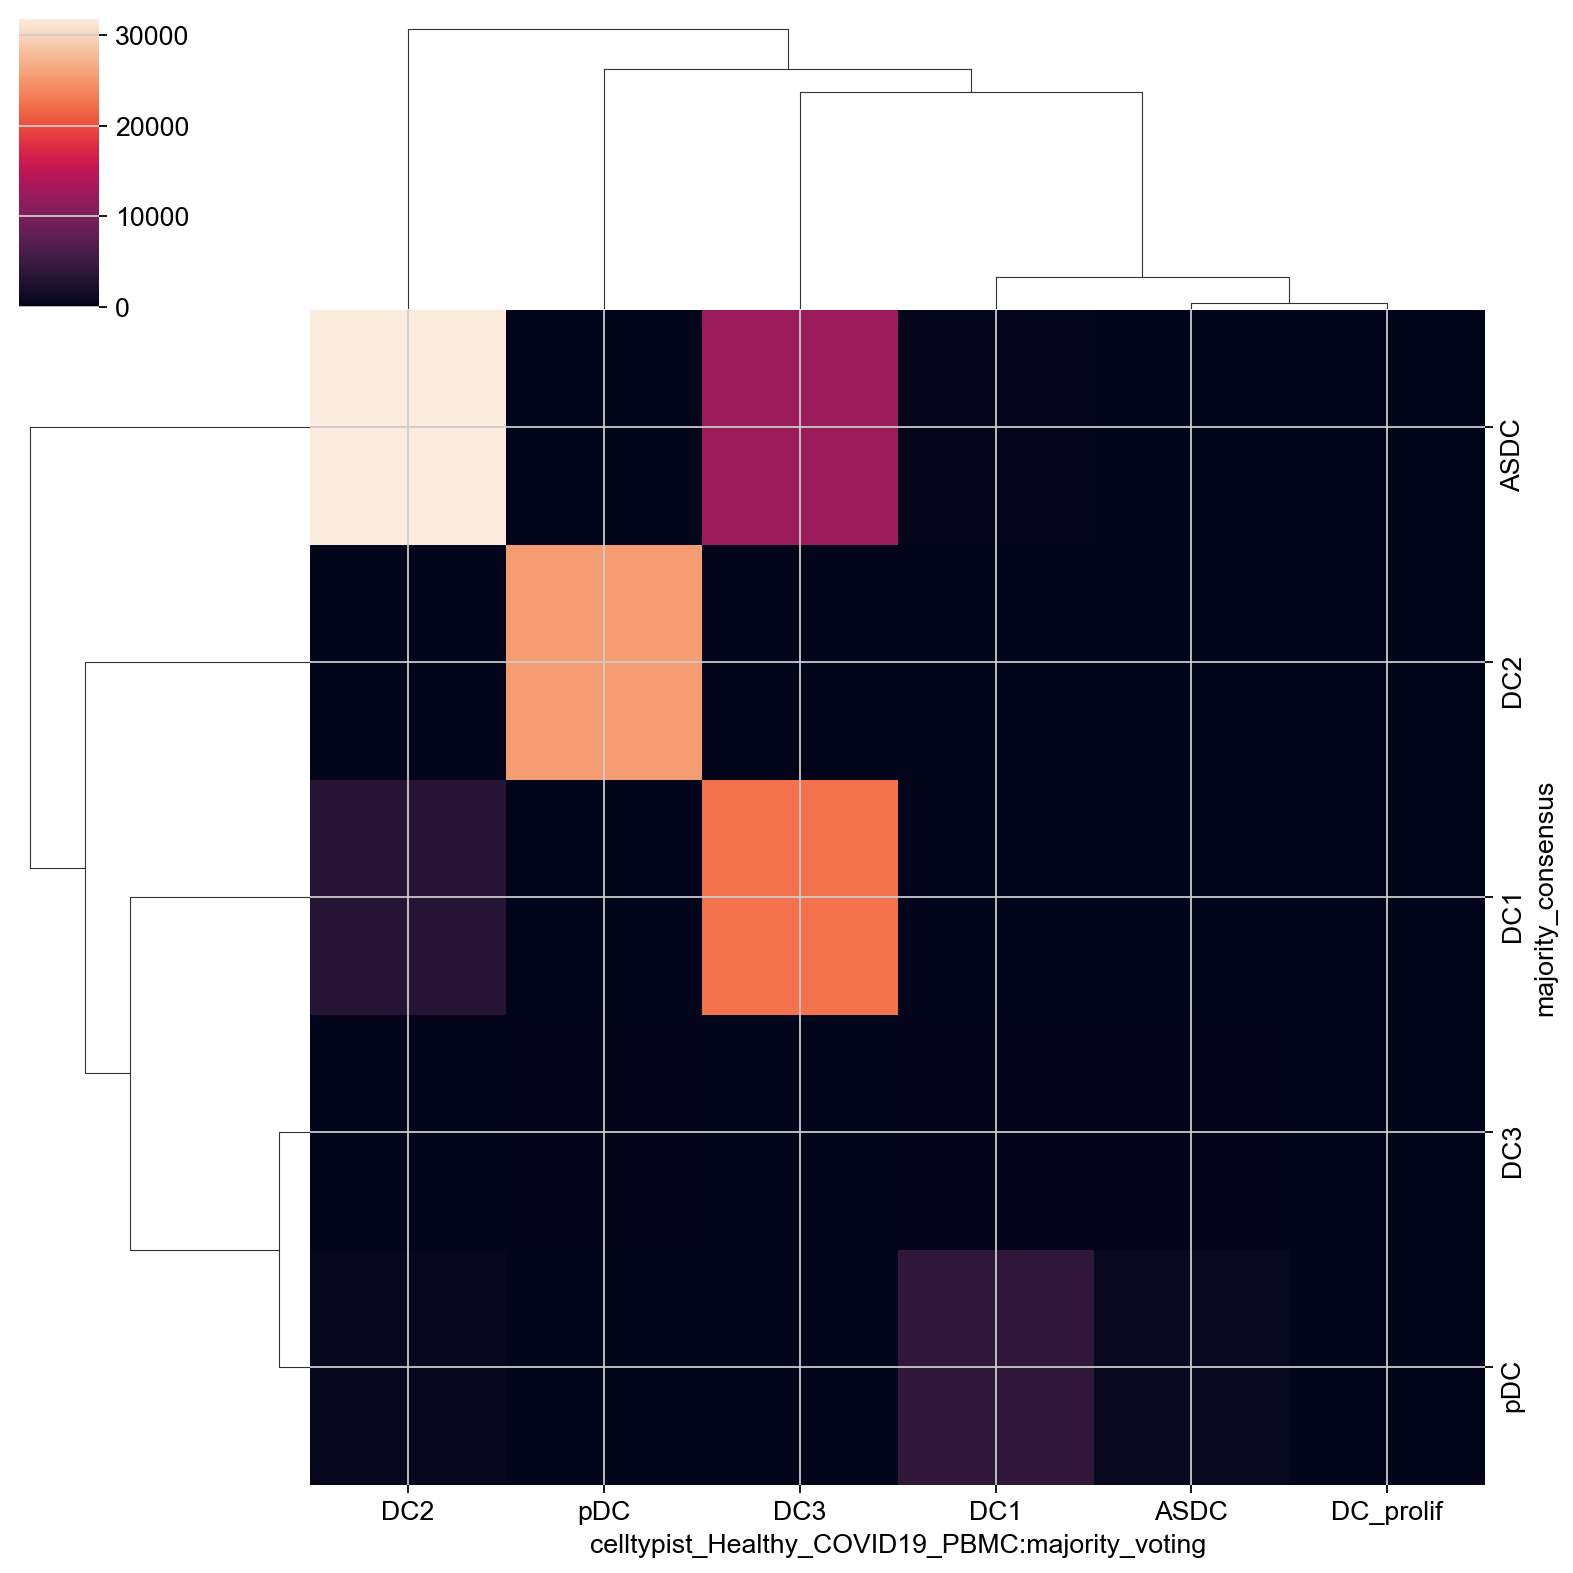

In [10]:
sns.clustermap(
    pd.crosstab(
        adata.obs['majority_consensus'],
        adata.obs['celltypist_Healthy_COVID19_PBMC:majority_voting']
    )
)

In [11]:
adata.obs['majority_consensus'] = pd.Categorical(
    adata.obs['majority_consensus'],
    categories=adata.obs['celltypist_Healthy_COVID19_PBMC:majority_voting'].cat.categories
)

In [12]:
colors = [
    'celltypist_COVID19_HumanChallenge_Blood:majority_voting',
    'celltypist_Healthy_COVID19_PBMC:majority_voting',
    'majority_consensus',
    'study',
    'sequenced_fragment',
    'assay',
    'disease_coarse',
]

In [13]:
adata.obs['3_vs_5_prime'] = adata.obs['assay'].map({
    '10x 3\' v2': '3_prime',
    '10x 3\' v3': '3_prime',
    '10x 5\' v1': '5_prime',
    '10x 5\' v2': '5_prime',
})

... storing '3_vs_5_prime' as categorical


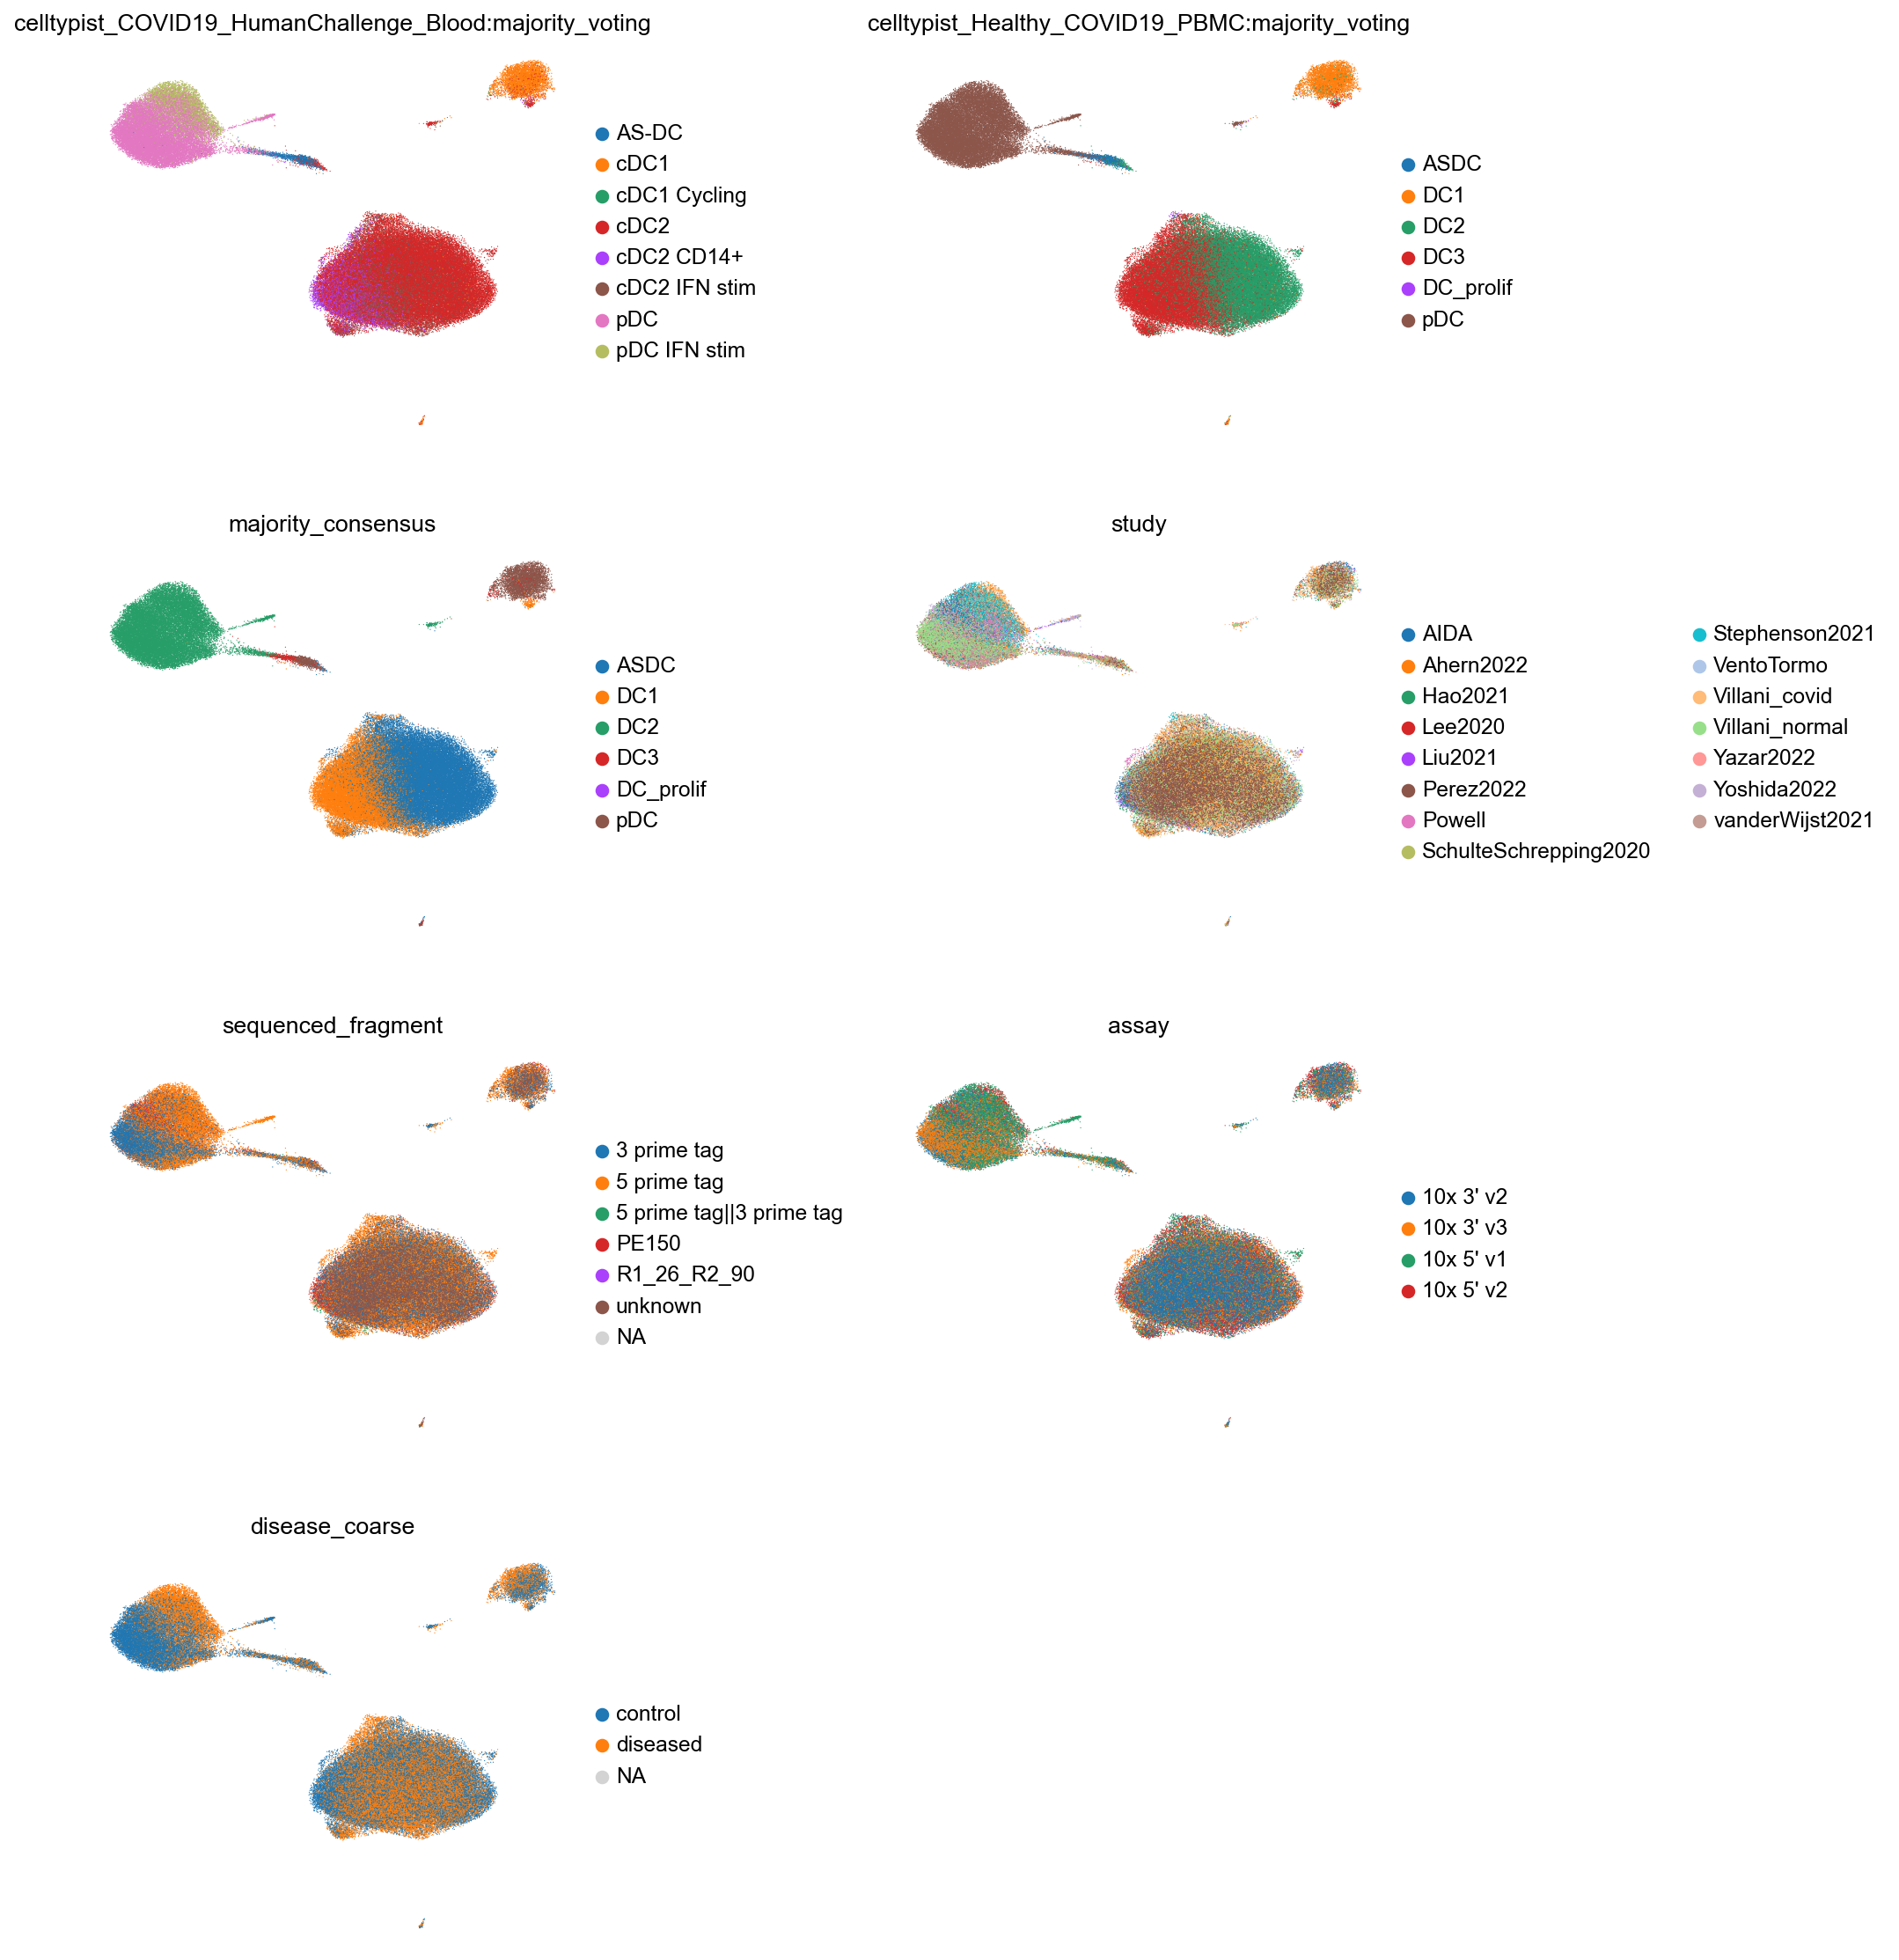

In [14]:
integration = integration_map['seurat']
sc.pl.embedding(
    adata,
    basis=f'X_umap--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    color=colors, # + [
    #     f'majority_reference--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    #     f'leiden_0.5_1--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    # ],
    ncols=2,
    wspace=0.5,
)

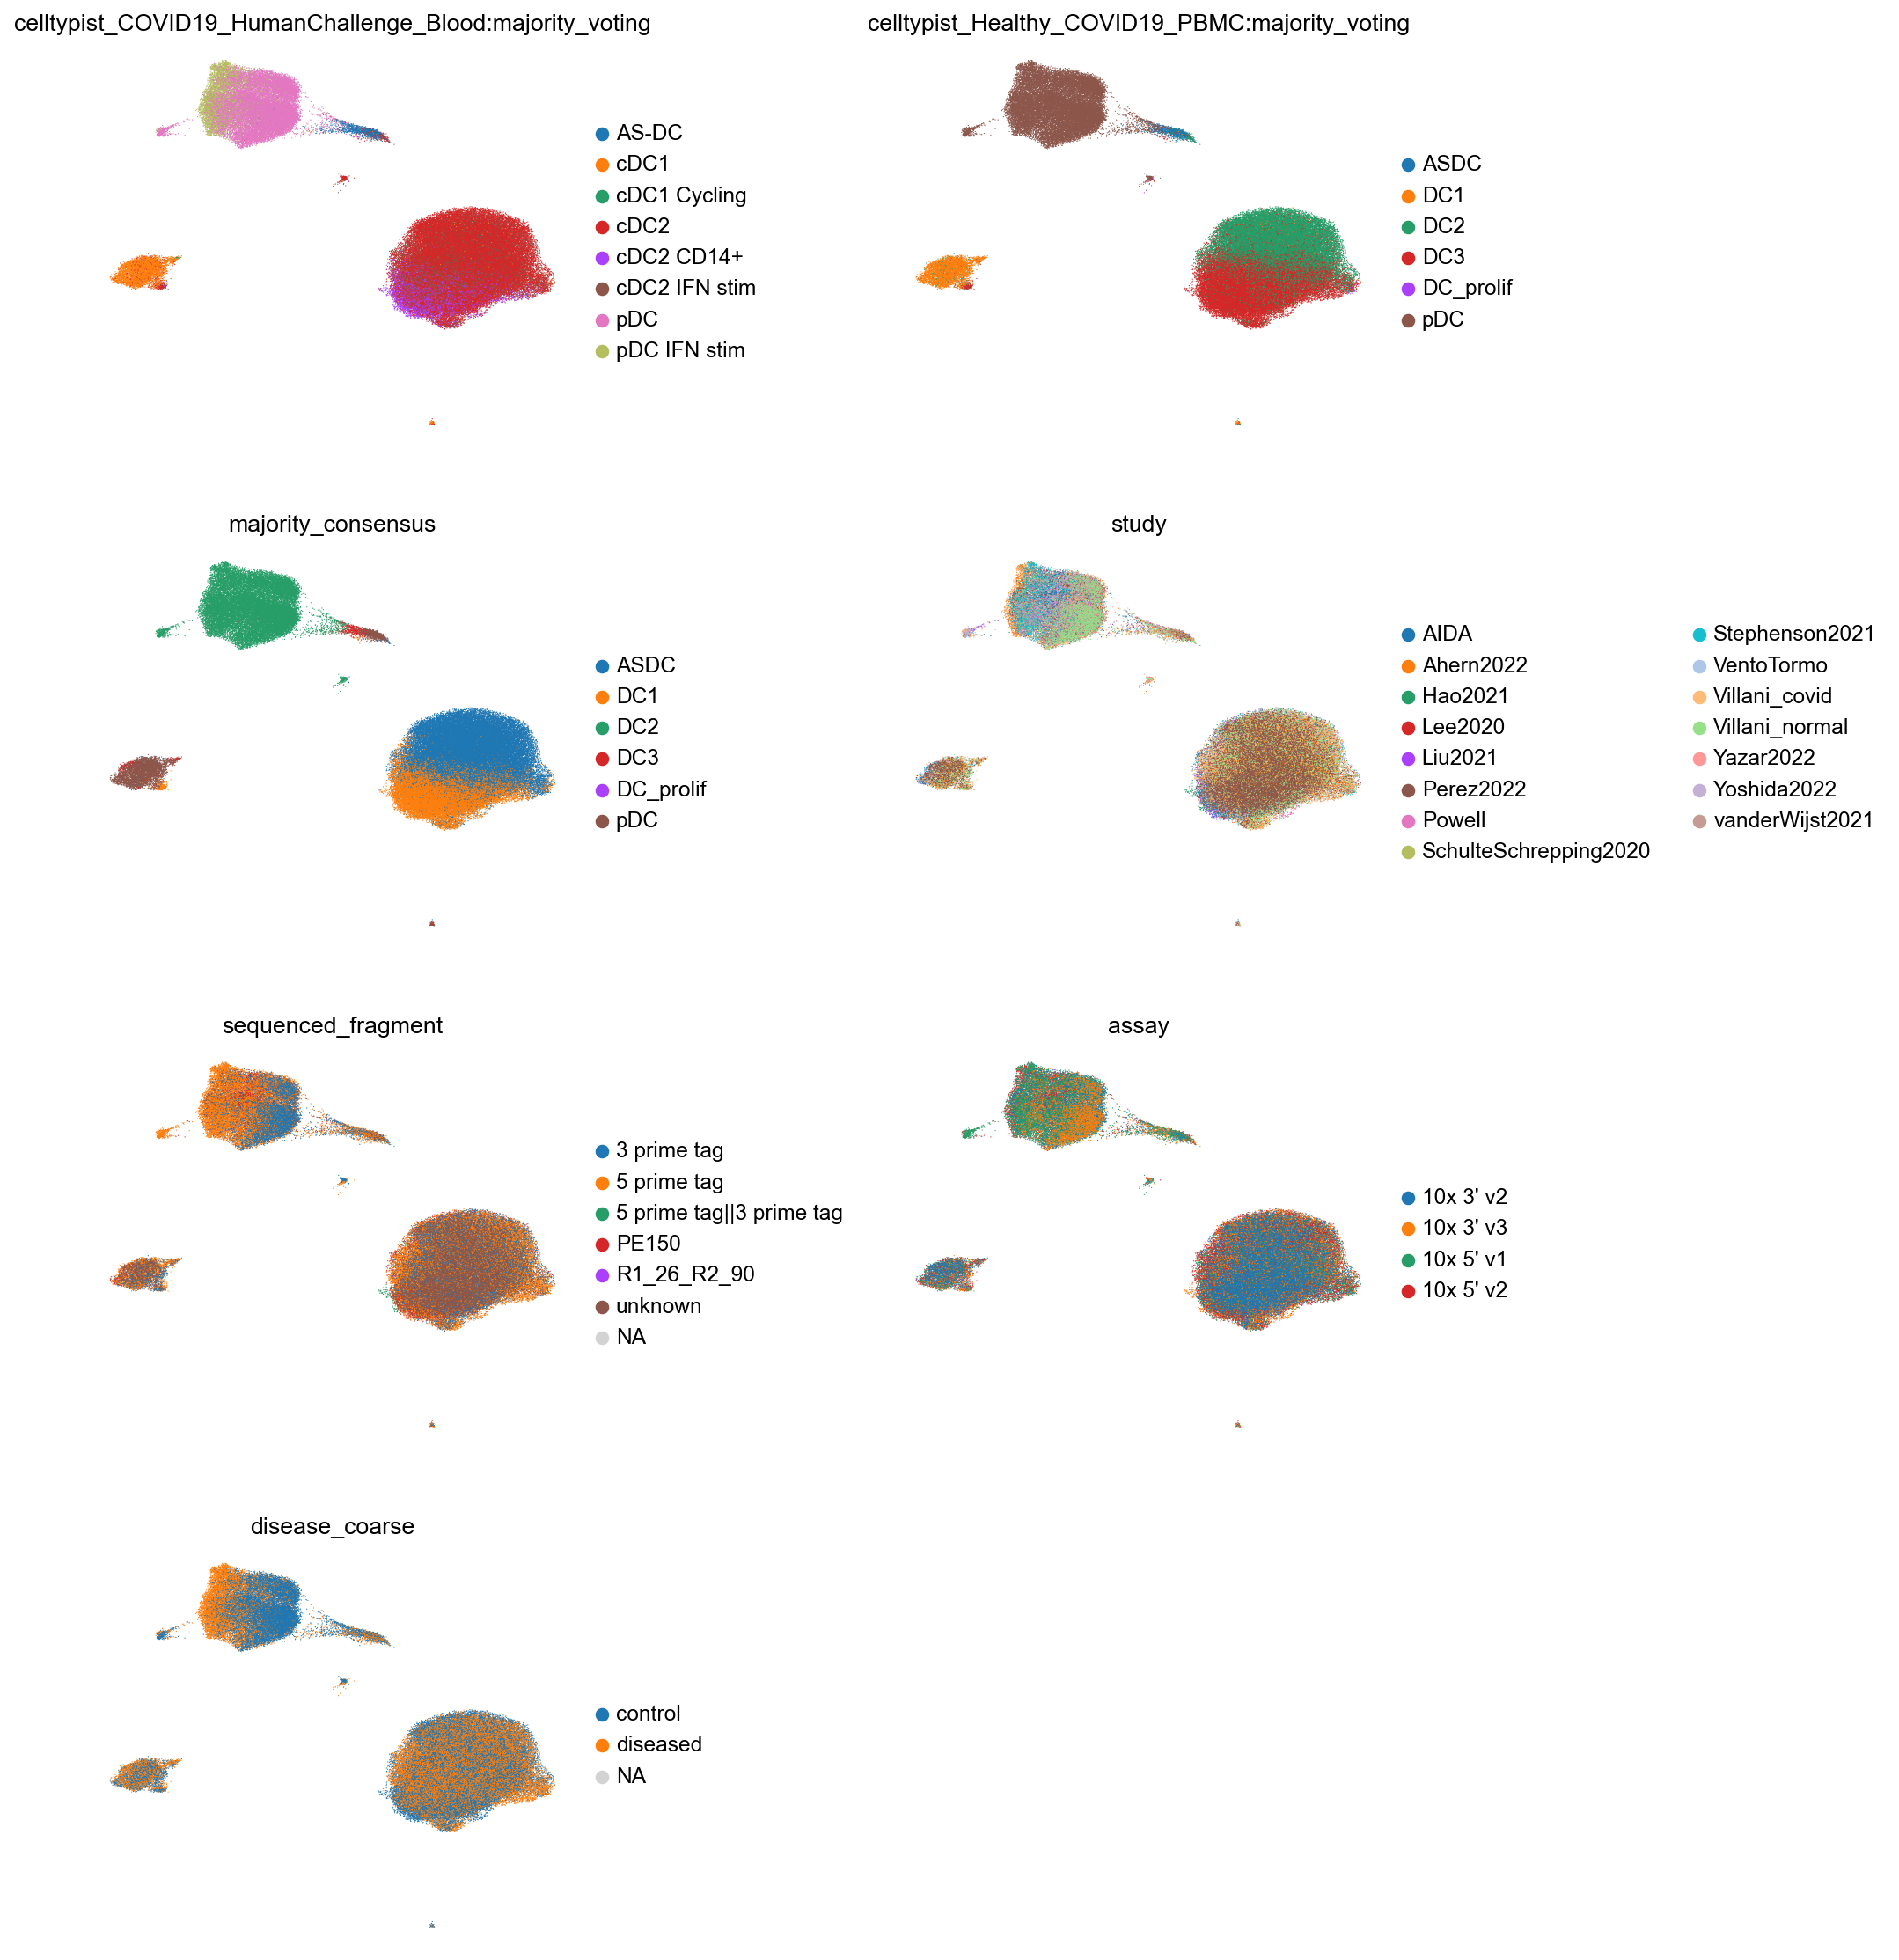

In [15]:
integration = integration_map['cell_ranger']
sc.pl.embedding(
    adata,
    basis=f'X_umap--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    color=colors, # + [
    #     f'majority_reference--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    #     f'leiden_0.5_1--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    # ],
    ncols=2,
    wspace=0.5,
)

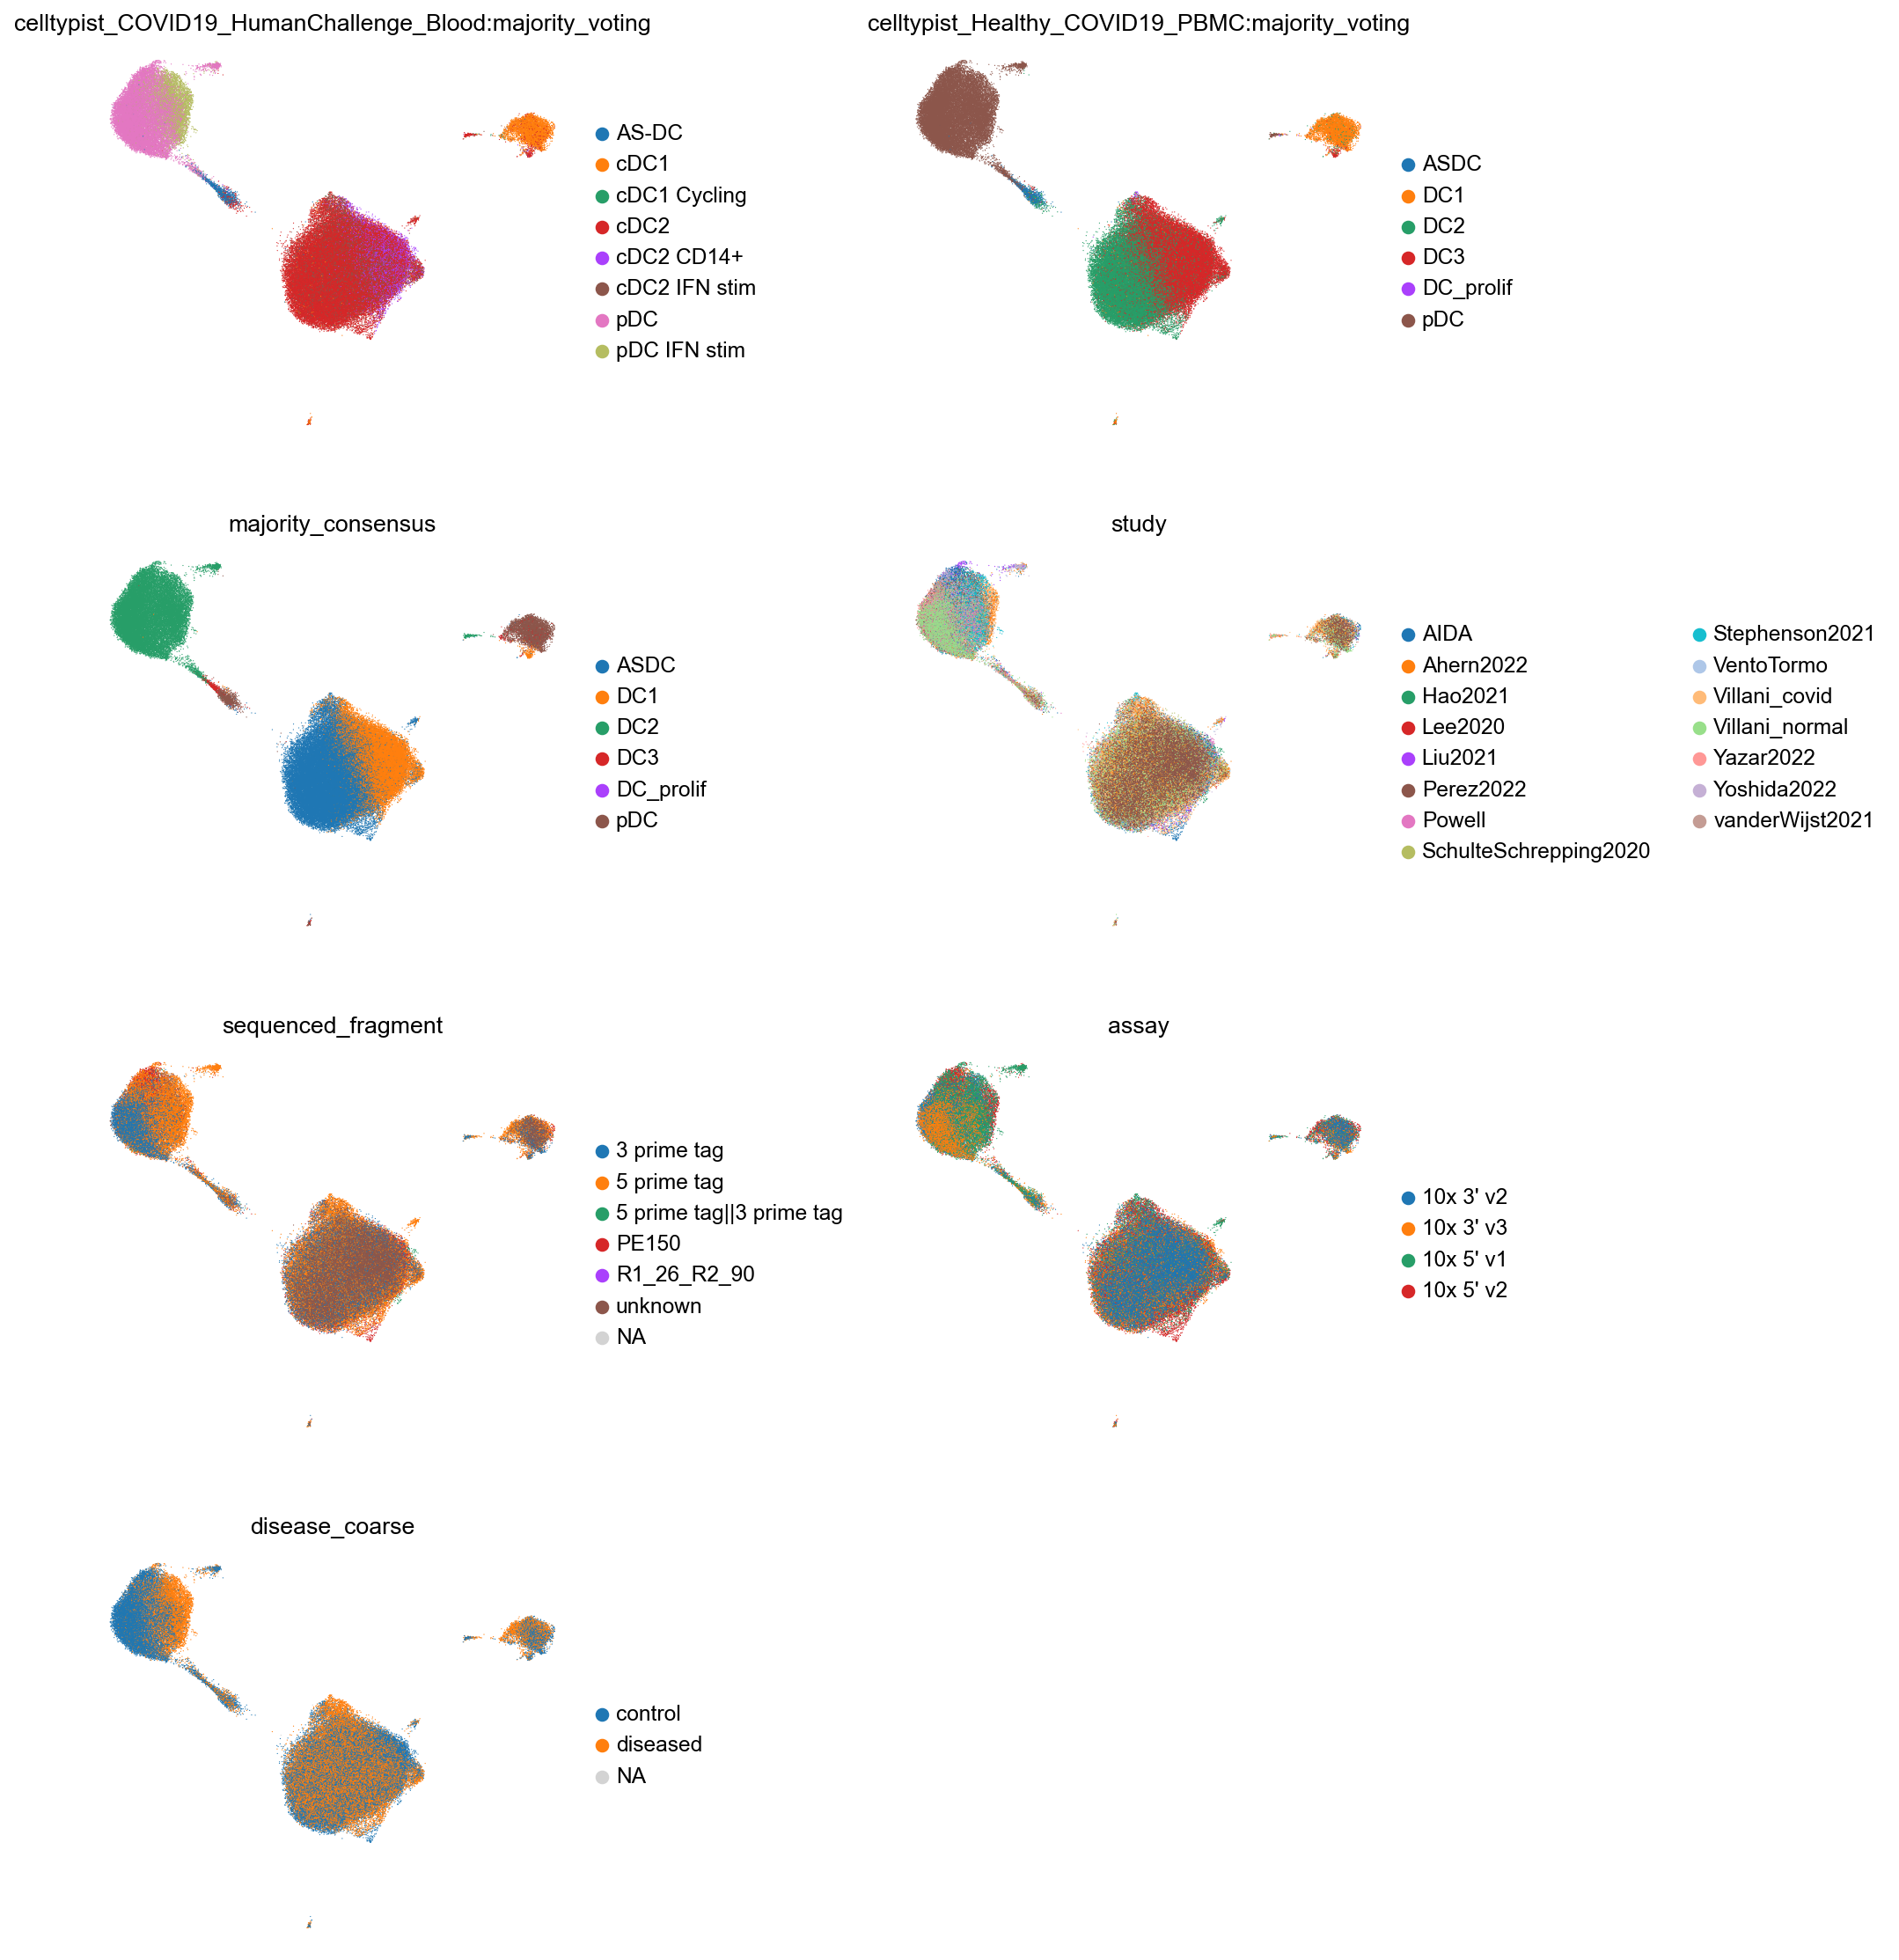

In [16]:
integration = integration_map['seurat_v3_paper']
sc.pl.embedding(
    adata,
    basis=f'X_umap--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    color=colors, # + [
    #     f'majority_reference--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    #     f'leiden_0.5_1--label_transfer:clustering:integration:preprocessing:filter:DC--integration={integration}',
    # ],
    ncols=2,
    wspace=0.5,
)

# Export data

In [17]:
output_dir = 'data/output/HICA/export'
file_name = 'hica_dcs.zarr'

In [18]:
hyperparams.to_csv(f'{output_dir}/hica_DC_hyperparams.csv', index=False, sep=';')

In [20]:
%%time
write_zarr(adata, f'{output_dir}/{file_name}')

CPU times: user 18.6 s, sys: 16.9 s, total: 35.5 s
Wall time: 1min 21s


In [21]:
ll -h {output_dir}

total 2.4G
-rw-r--r--  1 michaela.mueller 9.2K Feb 17 10:11 hica_DC_hyperparams.csv
drwxr-xr-x 11 michaela.mueller 4.0K Feb 17 10:12 hica_dcs.zarr/
-rw-r--r--  1 michaela.mueller 2.4G Feb 17 07:40 hica_dcs.zarr.tar.lz4


In [22]:
!du -hd1 {output_dir}/{file_name} | sort -h

12K	data/output/HICA/export/hica_dcs.zarr/obsp
12K	data/output/HICA/export/hica_dcs.zarr/varm
12K	data/output/HICA/export/hica_dcs.zarr/varp
1.4M	data/output/HICA/export/hica_dcs.zarr/var
23M	data/output/HICA/export/hica_dcs.zarr/obs
38M	data/output/HICA/export/hica_dcs.zarr/uns
532M	data/output/HICA/export/hica_dcs.zarr/obsm
843M	data/output/HICA/export/hica_dcs.zarr/X
1.4G	data/output/HICA/export/hica_dcs.zarr/layers
2.8G	data/output/HICA/export/hica_dcs.zarr


In [23]:
%%time
!cd {output_dir} && tar cf - {file_name} | lz4 -f -9 - {file_name}.tar.lz4

Compressed 2914150400 bytes into 2499086739 bytes ==> 85.76%                   
CPU times: user 459 ms, sys: 87.7 ms, total: 546 ms
Wall time: 1min 32s


In [24]:
!cd {output_dir} && ls -lh {file_name}.tar.lz4

-rw-r--r-- 1 michaela.mueller michaela.mueller.grp 2.4G Feb 17 10:14 hica_dcs.zarr.tar.lz4


### Upload to Onedrive

In [19]:
%%time
!rclone copy {output_dir}/hica_DC_hyperparams.csv onedrive:scAtlasTb/HICA/

CPU times: user 17.9 ms, sys: 19.6 ms, total: 37.5 ms
Wall time: 2.9 s


In [ ]:
# upload integration archive
!rclone copy {output_dir}/{file_name}.tar.lz4 onedrive:scAtlasTb/HICA/ \
    --log-level INFO \
    --stats 10s \
    --stats-one-line \
    --progress

74.277 MiB / 2.327 GiB, 3%, 7.778 MiB/s, ETA 4m56s150 MiB / 2.327 GiB, 6%, 7.301 MiB/s, ETA 5m5s240 MiB / 2.327 GiB, 10%, 8.410 MiB/s, ETA 4m14s330 MiB / 2.327 GiB, 14%, 8.873 MiB/s, ETA 3m51s404.277 MiB / 2.327 GiB, 17%, 8.163 MiB/s, ETA 4m2s486.543 MiB / 2.327 GiB, 20%, 8.022 MiB/s, ETA 3m56s570 MiB / 2.327 GiB, 24%, 8.133 MiB/s, ETA 3m42s640 MiB / 2.327 GiB, 27%, 7.926 MiB/s, ETA 3m39s730 MiB / 2.327 GiB, 31%, 8.099 MiB/s, ETA 3m24s816.480 MiB / 2.327 GiB, 34%, 8.417 MiB/s, ETA 3m6s900 MiB / 2.327 GiB, 38%, 8.683 MiB/s, ETA 2m50s974.277 MiB / 2.327 GiB, 41%, 7.943 MiB/s, ETA 2m57s1.035 GiB / 2.327 GiB, 44%, 7.908 MiB/s, ETA 2m47s1.101 GiB / 2.327 GiB, 47%, 7.727 MiB/s, ETA 2m42s1.182 GiB / 2.327 GiB, 51%, 8.151 MiB/s, ETA 2m23s1.253 GiB / 2.327 GiB, 54%, 7.545 MiB/s, ETA 2m25s1.335 GiB / 2.327 GiB, 57%, 7.756 MiB/s, ETA 2m11s1.416 GiB / 2.327 GiB, 61%, 7.865 MiB/s, ETA 1m58s1.494 GiB / 2.327 GiB, 64%, 7.794 MiB/s, ETA 1m49s

In [17]:
# upload models and diagnostic plots
model_dir = 'data/pipeline/feature_selection/HICA/integration/run_method/dataset~DC/file_id~preprocessing:filter:DC/batch~library_id/'
!rclone copy -P {model_dir} onedrive:scAtlasTb/HICA/DC_drvi_models/ \
    --include "*/*drvi*/model/**" \
    --include "*/*drvi*/plots/**" \
    --log-level NOTICE \
    --stats 5s \
    --stats-one-line  --dry-run


2026/02/18 04:05:31 INFO  : There was nothing to transfer
0 B / 0 B, -, 0 B/s, ETA -0 B / 0 B, -, 0 B/s, ETA -
2026/02/18 04:05:31 INFO  :           0 B / 0 B, -, 0 B/s, ETA -


In [21]:
# upload integration plots
!rclone copy -P data/images/feature_selection/HICA/integration/umap/dataset~DC/ onedrive:scAtlasTb/HICA/DC_images/ \
    --stats 10s \
    --stats-one-line \
    --log-level NOTICE

7.768 MiB / 45.006 MiB, 17%, 994.349 KiB/s, ETA 38s (xfr#9/87)20.737 MiB / 45.006 MiB, 46%, 1.075 MiB/s, ETA 22s (xfr#34/87)31.141 MiB / 45.006 MiB, 69%, 1.111 MiB/s, ETA 12s (xfr#57/87)43.974 MiB / 45.006 MiB, 98%, 1.198 MiB/s, ETA 0s (xfr#82/87)45.006 MiB / 45.006 MiB, 100%, 1.171 MiB/s, ETA 0s
